In [1]:
import pandas as pd

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

In [3]:
df = pd.read_csv("../data/processed/clean_sales.csv", encoding="latin1")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Year,Month,Quarter,Weekday,Profit Margin,Sales Category
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2,0.00,41.9136,2016.0,November,4.0,Tuesday,16.00,Medium
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3,0.00,219.5820,2016.0,November,4.0,Tuesday,30.00,High
2,3,CA-2016-138688,2016-06-12,NaN,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2,0.00,6.8714,2016.0,June,2.0,Sunday,47.00,Low
3,4,US-2015-108966,2015-10-11,NaN,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5,0.45,-383.0310,2015.0,October,4.0,Sunday,-40.00,High
4,5,US-2015-108966,2015-10-11,NaN,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2,0.20,2.5164,2015.0,October,4.0,Sunday,11.25,Low


In [5]:
df.shape

(9994, 27)

In [6]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit',
 'Year',
 'Month',
 'Quarter',
 'Weekday',
 'Profit Margin',
 'Sales Category']

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          9994 non-null   int64  
 1   Order ID        9994 non-null   str    
 2   Order Date      4042 non-null   str    
 3   Ship Date       3898 non-null   str    
 4   Ship Mode       9994 non-null   str    
 5   Customer ID     9994 non-null   str    
 6   Customer Name   9994 non-null   str    
 7   Segment         9994 non-null   str    
 8   Country         9994 non-null   str    
 9   City            9994 non-null   str    
 10  State           9994 non-null   str    
 11  Postal Code     9994 non-null   int64  
 12  Region          9994 non-null   str    
 13  Product ID      9994 non-null   str    
 14  Category        9994 non-null   str    
 15  Sub-Category    9994 non-null   str    
 16  Product Name    9994 non-null   str    
 17  Sales           9994 non-null   float64
 18 

In [8]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Year,Quarter,Profit Margin
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,4042.000000,4042.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896,2015.723404,2.940376,12.031393
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108,1.119750,1.044261,46.675435
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000,2014.000000,1.000000,-275.000000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750,2015.000000,2.000000,7.500000
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500,2016.000000,3.000000,27.000000
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000,2017.000000,4.000000,36.250000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000,2017.000000,4.000000,50.000000


In [9]:
missing = df.isnull().sum()

print(missing)

Row ID               0
Order ID             0
Order Date        5952
Ship Date         6096
Ship Mode            0
Customer ID          0
Customer Name        0
Segment              0
Country              0
City                 0
State                0
Postal Code          0
Region               0
Product ID           0
Category             0
Sub-Category         0
Product Name         0
Sales                0
Quantity             0
Discount             0
Profit               0
Year              5952
Month             5952
Quarter           5952
Weekday           5952
Profit Margin        0
Sales Category       0
dtype: int64


In [10]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

print(missing_percentage)

Ship Date         60.996598
Order Date        59.555733
Quarter           59.555733
Month             59.555733
Year              59.555733
Weekday           59.555733
Customer Name      0.000000
Order ID           0.000000
Ship Mode          0.000000
Customer ID        0.000000
Row ID             0.000000
State              0.000000
City               0.000000
Country            0.000000
Segment            0.000000
Postal Code        0.000000
Region             0.000000
Product ID         0.000000
Category           0.000000
Quantity           0.000000
Sales              0.000000
Product Name       0.000000
Sub-Category       0.000000
Discount           0.000000
Profit             0.000000
Profit Margin      0.000000
Sales Category     0.000000
dtype: float64


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
print(df["Category"].unique())

<StringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str


In [13]:
print(df["Region"].unique())

<StringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str


In [14]:
print(df["Segment"].unique())

<StringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str


In [15]:
print(df["Category"].value_counts())

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64


In [16]:
total_sales = df["Sales"].sum()

total_profit = df["Profit"].sum()

total_orders = df["Order ID"].nunique()

total_customers = df["Customer Name"].nunique()

total_products = df["Product Name"].nunique()

average_order_value = total_sales / total_orders

profit_margin = (total_profit / total_sales) * 100

In [17]:
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Average Order Value:", round(average_order_value, 2))
print("Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Total Products: 1850
Average Order Value: 458.61
Profit Margin: 12.47 %


In [18]:
df["Sales"].describe()

count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64

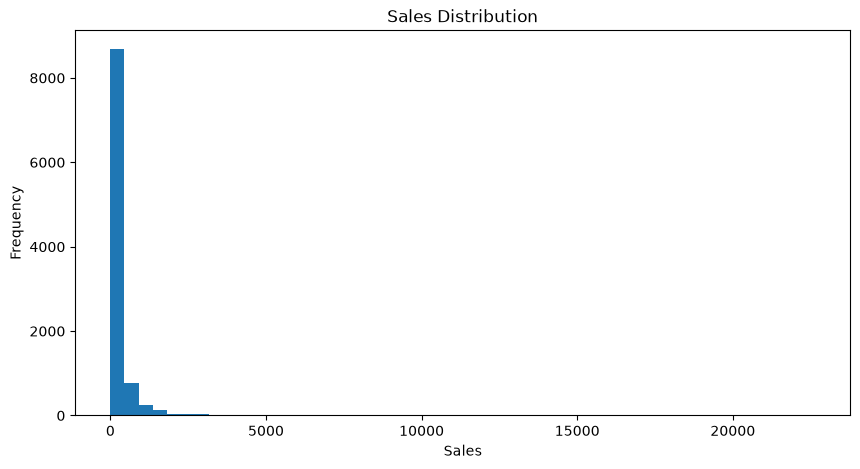

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(df["Sales"], bins=50)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

In [20]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(category_profit)

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


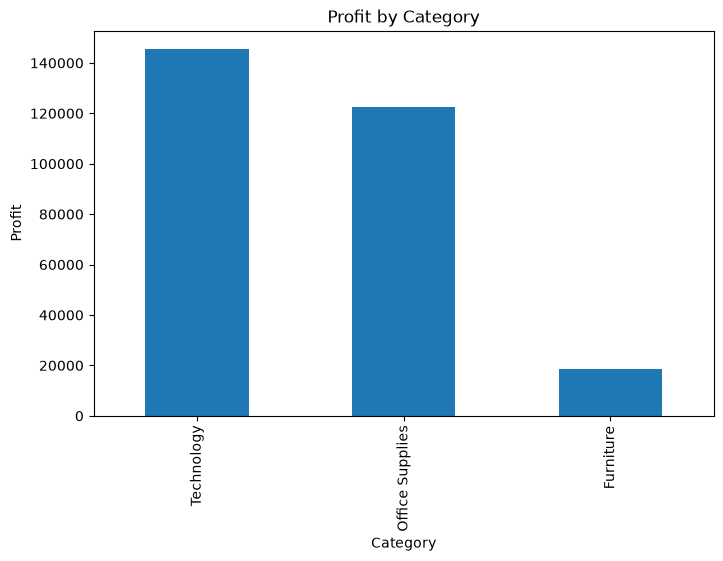

In [21]:
category_profit.plot(kind="bar", figsize=(8, 5))

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")

plt.show()

In [22]:
region_summary = (
    df.groupby("Region")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

print(region_summary)

               Sales       Profit  Orders
Region                                   
West     725457.8245  108418.4489    1611
East     678781.2400   91522.7800    1401
Central  501239.8908   39706.3625    1175
South    391721.9050   46749.4303     822


In [23]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [24]:
monthly_sales = (
    df.groupby(
        df["Order Date"].dt.to_period("M")
    )["Sales"]
    .sum()
)

print(monthly_sales)

Order Date
2014-01     4923.6160
2014-02     3610.4020
2014-03     8048.7730
2014-04    16040.8110
2014-05     9288.8640
2014-06    17235.9460
2014-07     8827.5750
2014-08    16852.6840
2014-09    32826.0590
2014-10     7004.0870
2014-11    32603.2822
2014-12    21644.5905
2015-01     6528.3756
2015-02     4241.3740
2015-03    10057.0474
2015-04     8101.9360
2015-05     9681.4540
2015-06     9047.7420
2015-07    10741.6690
2015-08    10603.9792
2015-09    14351.4900
2015-10    12066.0725
2015-11    37379.2940
2015-12    31413.0510
2016-01     6836.8480
2016-02    17039.1400
2016-03    28157.2050
2016-04    15854.1550
2016-05    14800.8650
2016-06    16969.9960
2016-07    13059.8470
2016-08     8931.7085
2016-09    41214.5446
2016-10    30056.2490
2016-11    33052.1888
2016-12    45517.1060
2017-01    11076.9750
2017-02     7278.1000
2017-03    10997.7420
2017-04    18896.3015
2017-05    19357.8208
2017-06    17888.3560
2017-07    15992.8080
2017-08    14269.2740
2017-09    36850.9140

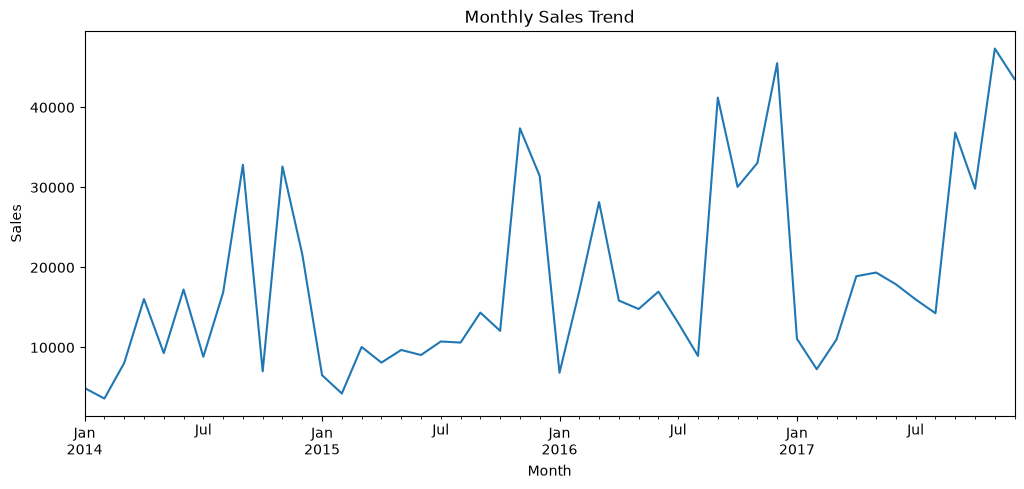

In [25]:
monthly_sales.plot(
    figsize=(12, 5)
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.show()

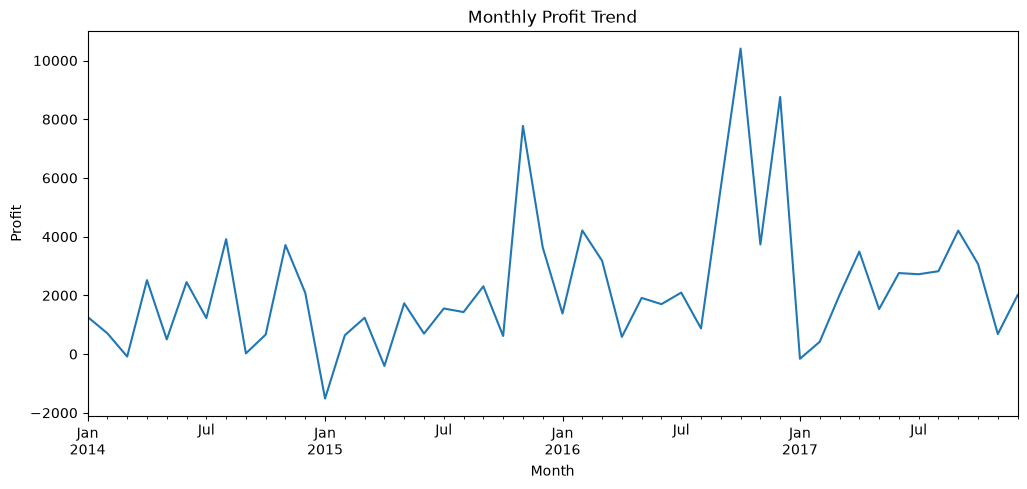

In [26]:
monthly_profit = (
    df.groupby(
        df["Order Date"].dt.to_period("M")
    )["Profit"]
    .sum()
)

monthly_profit.plot(figsize=(12, 5))

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")

plt.show()

In [27]:
discount_profit = (
    df.groupby("Category")
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Profit=("Profit", "mean"),
        Total_Profit=("Profit", "sum")
    )
)

print(discount_profit)

                 Average_Sales  Average_Profit  Total_Profit
Category                                                    
Furniture           349.834887        8.699327    18451.2728
Office Supplies     119.324101       20.327050   122490.8008
Technology          452.709276       78.752002   145454.9481


In [28]:
# Select only numeric columns
numeric_cols = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Profit Margin"
]

# Convert columns to numeric
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")

# Calculate correlation
correlation = df[numeric_cols].corr()

print(correlation)

                  Sales  Quantity  Discount    Profit  Profit Margin
Sales          1.000000  0.200795 -0.028190  0.479064       0.003444
Quantity       0.200795  1.000000  0.008623  0.066253      -0.005280
Discount      -0.028190  0.008623  1.000000 -0.219487      -0.864452
Profit         0.479064  0.066253 -0.219487  1.000000       0.223732
Profit Margin  0.003444 -0.005280 -0.864452  0.223732       1.000000


In [29]:
print(df[["Order Date", "Ship Date", "Year", "Quarter"]].isnull().sum())

Order Date    5952
Ship Date     6096
Year          5952
Quarter       5952
dtype: int64


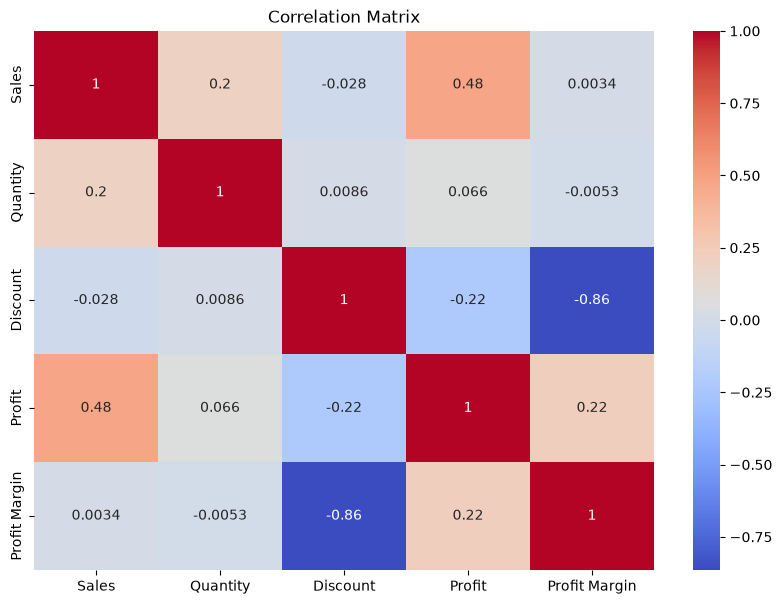

In [30]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

In [31]:
Q1 = df["Sales"].quantile(0.25)

Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Sales"] < lower_bound) |
    (df["Sales"] > upper_bound)
]

print("Sales outliers:", len(outliers))

Sales outliers: 1167


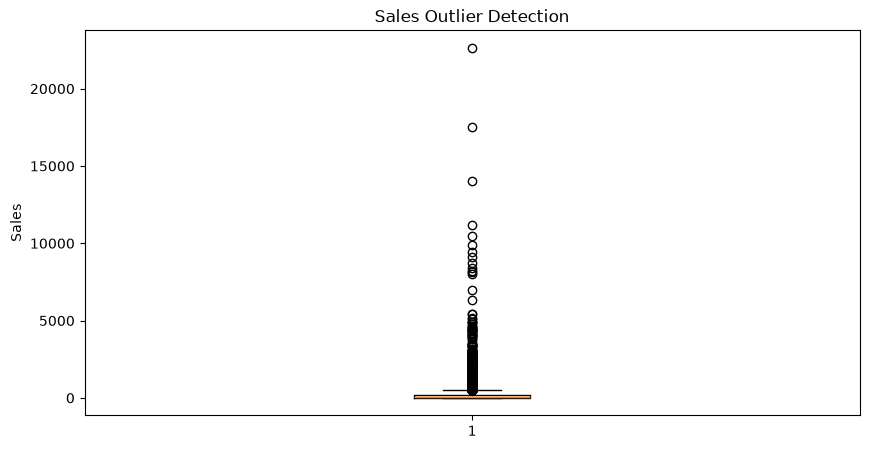

In [32]:
plt.figure(figsize=(10, 5))

plt.boxplot(df["Sales"])

plt.title("Sales Outlier Detection")
plt.ylabel("Sales")

plt.show()

In [33]:
correlation, p_value = stats.pearsonr(
    df["Discount"],
    df["Profit"]
)

print("Correlation:", correlation)
print("P-value:", p_value)

Correlation: -0.21948745637176847
P-value: 2.7022944361957867e-109


In [34]:
no_discount = df[
    df["Discount"] == 0
]["Profit"]

discounted = df[
    df["Discount"] > 0
]["Profit"]

In [35]:
t_stat, p_value = stats.ttest_ind(
    no_discount,
    discounted,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 15.737992941015493
P-value: 4.3569303711413974e-55


In [36]:
no_discount = df[df["Discount"] == 0]["Profit"]
discount = df[df["Discount"] > 0]["Profit"]

print("Average Profit - No Discount:", no_discount.mean())
print("Average Profit - Discount:", discount.mean())

print("T-statistic:", t_stat)
print("P-value:", p_value)

Average Profit - No Discount: 66.90029245518967
Average Profit - Discount: -6.657155792917629
T-statistic: 15.737992941015493
P-value: 4.3569303711413974e-55


Exact discount levels

In [38]:
# Average profit for each discount level

discount_profit = (
    df.groupby("Discount")["Profit"]
      .agg(["count", "mean", "sum"])
      .reset_index()
)

discount_profit.columns = [
    "Discount",
    "Number of Orders",
    "Average Profit",
    "Total Profit"
]

print(discount_profit)

    Discount  Number of Orders  Average Profit  Total Profit
0       0.00              4798       66.900292   320987.6032
1       0.10                94       96.055074     9029.1770
2       0.15                52       27.288298     1418.9915
3       0.20              3657       24.702572    90337.3060
4       0.30               227      -45.679636   -10369.2774
5       0.32                27      -88.560656    -2391.1377
6       0.40               206     -111.927429   -23057.0504
7       0.45                11     -226.646464    -2493.1111
8       0.50                66     -310.703456   -20506.4281
9       0.60               138      -43.077212    -5944.6552
10      0.70               418      -95.874060   -40075.3569
11      0.80               300     -101.796797   -30539.0392


In [39]:
discount_profit = (
    df.groupby("Discount")["Profit"]
      .agg(["count", "mean", "sum"])
      .reset_index()
)

discount_profit.columns = [
    "Discount",
    "Number of Orders",
    "Average Profit",
    "Total Profit"
]

discount_profit["Discount"] = discount_profit["Discount"] * 100

discount_profit["Average Profit"] = discount_profit["Average Profit"].round(2)

discount_profit["Total Profit"] = discount_profit["Total Profit"].round(2)

print(discount_profit)

    Discount  Number of Orders  Average Profit  Total Profit
0        0.0              4798           66.90     320987.60
1       10.0                94           96.06       9029.18
2       15.0                52           27.29       1418.99
3       20.0              3657           24.70      90337.31
4       30.0               227          -45.68     -10369.28
5       32.0                27          -88.56      -2391.14
6       40.0               206         -111.93     -23057.05
7       45.0                11         -226.65      -2493.11
8       50.0                66         -310.70     -20506.43
9       60.0               138          -43.08      -5944.66
10      70.0               418          -95.87     -40075.36
11      80.0               300         -101.80     -30539.04


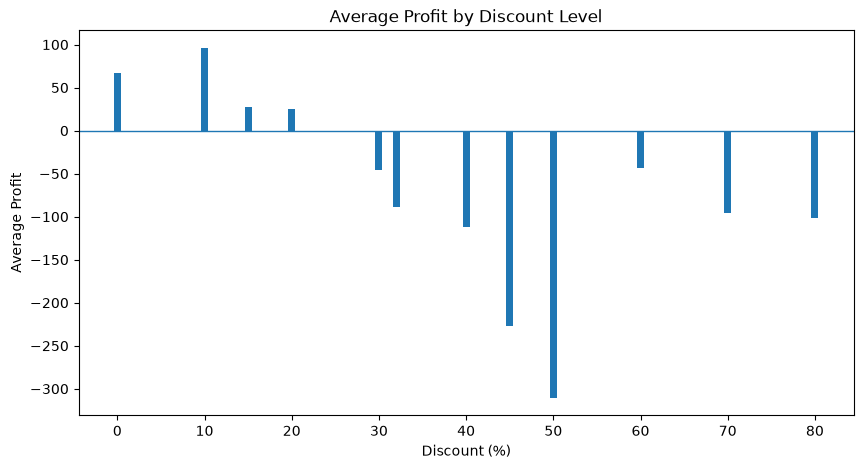

In [40]:
import matplotlib.pyplot as plt

avg_profit = df.groupby("Discount")["Profit"].mean()

plt.figure(figsize=(10, 5))

plt.bar(
    avg_profit.index * 100,
    avg_profit.values
)

plt.xlabel("Discount (%)")
plt.ylabel("Average Profit")
plt.title("Average Profit by Discount Level")
plt.axhline(0, linewidth=1)

plt.show()

In [41]:
discount_profit = (
    df.groupby("Discount")["Profit"]
      .agg(["count", "mean", "sum"])
      .reset_index()
)

discount_profit.columns = [
    "Discount",
    "Number of Orders",
    "Average Profit",
    "Total Profit"
]

discount_profit["Discount"] *= 100

discount_profit = discount_profit.round(2)

print(discount_profit)

    Discount  Number of Orders  Average Profit  Total Profit
0        0.0              4798           66.90     320987.60
1       10.0                94           96.06       9029.18
2       15.0                52           27.29       1418.99
3       20.0              3657           24.70      90337.31
4       30.0               227          -45.68     -10369.28
5       32.0                27          -88.56      -2391.14
6       40.0               206         -111.93     -23057.05
7       45.0                11         -226.65      -2493.11
8       50.0                66         -310.70     -20506.43
9       60.0               138          -43.08      -5944.66
10      70.0               418          -95.87     -40075.36
11      80.0               300         -101.80     -30539.04
